# Case study: cohesive directed communities in an author citation network

This notebook reproduces the case study of the paper *Maximal Directed $k$-Plex Mining* (IEEE BigData 2026), Section VIII and Fig. 7.

A **$(k_1,k_2)$-plex** is a vertex set in which every vertex misses at most $k_1$ out-neighbors and at most $k_2$ in-neighbors (counting itself).
We mine $(2,2)$-plexes in a network where an edge $u \to v$ means that author $u$ cited author $v$, and compare them with ordinary (undirected) 2-plexes.

**Before running:** build the programs with `make` in the repository root.

In [1]:
from IPython.display import Image, display
from plexlib import (build_author_graph, describe, download_citation_data, draw_plex, find,
                     load_graph, load_names, load_plexes, run_kplex, OUTPUT)
import os

## 1. Data
The citation data set of [ArnetMiner](https://lfs.aminer.cn/lab-datasets/soinf/) (2,555 papers in 10 topics such as data mining and databases) is downloaded on first use.
Papers cite only older papers, so we derive an **author citation network**: $u \to v$ if a paper (co-)authored by $u$ cites a paper (co-)authored by $v$.

In [2]:
raw = download_citation_data()
paths = build_author_graph(raw)
names = load_names(paths['authors.tsv'])
edges = load_graph(paths['author_graph.txt'])
ids = {n: i for i, n in names.items()}

2555 papers, 6101 citations -> 2160 authors, 19185 citation edges


## 2. Mining
`run_kplex` calls the compiled program `serial/kplex` with `-o`, which writes one maximal plex per line.
We mine $(2,2)$-plexes with $q=8$ on the directed graph, and 2-plexes with $q=12$ on the undirected version (every edge made bidirectional).

In [3]:
directed, ms = run_kplex(paths['author_graph.txt'], 2, 2, 8, 'plexes_directed_k2-2_q8.txt')
plexes = load_plexes(directed)
print(f'(2,2)-plexes, q = 8: {len(plexes)} found in {ms} ms')

undirected, ms = run_kplex(paths['author_graph_undirected.txt'], 2, 2, 12, 'plexes_undirected_k2_q12.txt')
uplexes = load_plexes(undirected)
print(f'undirected 2-plexes, q = 12: {len(uplexes)} found in {ms} ms')

(2,2)-plexes, q = 8: 118 found in 23 ms
undirected 2-plexes, q = 12: 65509 found in 1905 ms


## 3. A $(2,2)$-plex of database researchers (Fig. 7(a))
All authors cite each other except that Jennifer Widom does not cite Anthony Tomasic, so Tomasic misses two incoming links (from Widom and from itself) and Widom misses two outgoing links.

  Anthony Tomasic              in  8  out  9  | not cited by: Jennifer Widom
  Donald Kossmann              in  9  out  9
  Edward L. Wimmers            in  9  out  9
  Hector Garcia-Molina         in  9  out  9
  Jennifer Widom               in  9  out  8  | does not cite: Anthony Tomasic
  Jun Yang                     in  9  out  9
  Laura M. Haas                in  9  out  9
  Louiqa Raschid               in  9  out  9
  Patrick Valduriez            in  9  out  9
  Yannis Papakonstantinou      in  9  out  9


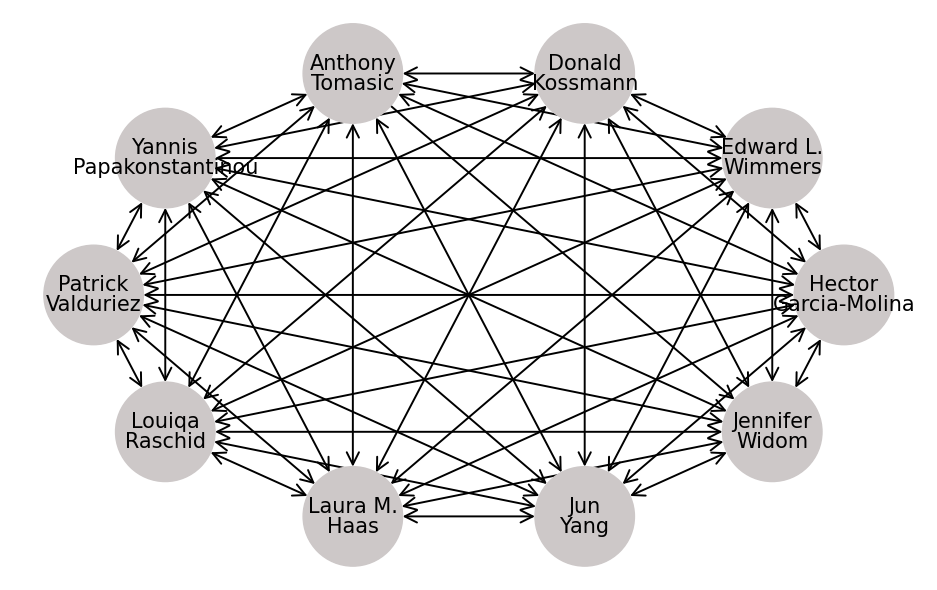

In [4]:
(a,) = find(plexes, names, ['Anthony Tomasic', 'Jennifer Widom'], size=10)
print(describe(a, edges, names))
display(Image(draw_plex(a, edges, names, os.path.join(OUTPUT, 'fig7a_db_plex.png'))))

## 4. A $(2,2)$-plex of data mining researchers (Fig. 7(b))
Two one-way citations: Ng cites Srikant (not cited back) and Fu cites Ng (not cited back), so Ng reaches both bounds.

  Jiawei Han                   in  7  out  7
  Jong Soo Park                in  7  out  7
  Ming-Syan Chen               in  7  out  7
  Philip S. Yu                 in  7  out  7
  Rakesh Agrawal               in  7  out  7
  Ramakrishnan Srikant         in  7  out  6  | does not cite: Raymond T. Ng
  Raymond T. Ng                in  6  out  6  | does not cite: Yongjian Fu  | not cited by: Ramakrishnan Srikant
  Yongjian Fu                  in  6  out  7  | not cited by: Raymond T. Ng


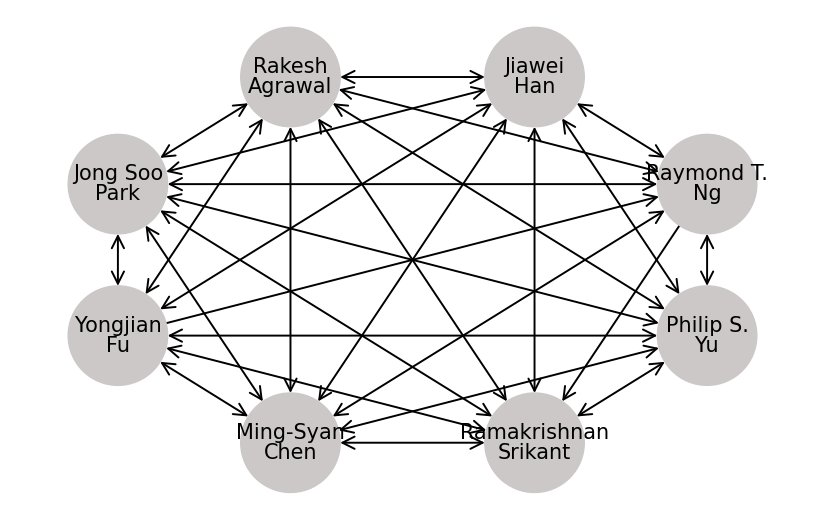

In [5]:
dm = ['Rakesh Agrawal', 'Jiawei Han', 'Raymond T. Ng', 'Philip S. Yu',
      'Ramakrishnan Srikant', 'Ming-Syan Chen', 'Yongjian Fu', 'Jong Soo Park']
(b,) = find(plexes, names, dm, size=len(dm))
print(describe(b, edges, names))
display(Image(draw_plex(b, edges, names, os.path.join(OUTPUT, 'fig7b_dm_plex.png'), order=[ids[n] for n in dm])))

## 5. Ignoring directions hides this community (Fig. 7(c))
In the undirected graph, the 8 authors above are contained in larger 2-plexes, so their community is not maximal there and is never reported.
These larger 2-plexes also contain authors with very one-sided citation links: A. Inkeri Verkamo is cited by 11 members (red) but cites none of them.

11 undirected 2-plexes contain all 8 authors; sizes: [13, 13, 13, 13, 13, 13, 12, 12, 12, 12, 12]
  A. Inkeri Verkamo            in 11  out  0  | does not cite: Ada Wai-Chee Fu, C. Y. Wong, David Wai-Lok Cheung, Jiawei Han, Jong Soo Park, Ming-Syan Chen, Philip S. Yu, Rakesh Agrawal, Ramakrishnan Srikant, Raymond T. Ng, Vincent T. Y. Ng, Yongjian Fu  | not cited by: Raymond T. Ng
  Ada Wai-Chee Fu              in  2  out 12  | not cited by: A. Inkeri Verkamo, C. Y. Wong, Jong Soo Park, Ming-Syan Chen, Philip S. Yu, Rakesh Agrawal, Ramakrishnan Srikant, Raymond T. Ng, Vincent T. Y. Ng, Yongjian Fu
  C. Y. Wong                   in  7  out  9  | does not cite: Ada Wai-Chee Fu, David Wai-Lok Cheung, Vincent T. Y. Ng  | not cited by: A. Inkeri Verkamo, Jong Soo Park, Rakesh Agrawal, Ramakrishnan Srikant, Raymond T. Ng
  David Wai-Lok Cheung         in  6  out 12  | not cited by: A. Inkeri Verkamo, C. Y. Wong, Jong Soo Park, Rakesh Agrawal, Ramakrishnan Srikant, Raymond T. Ng
  Jiawei Han  

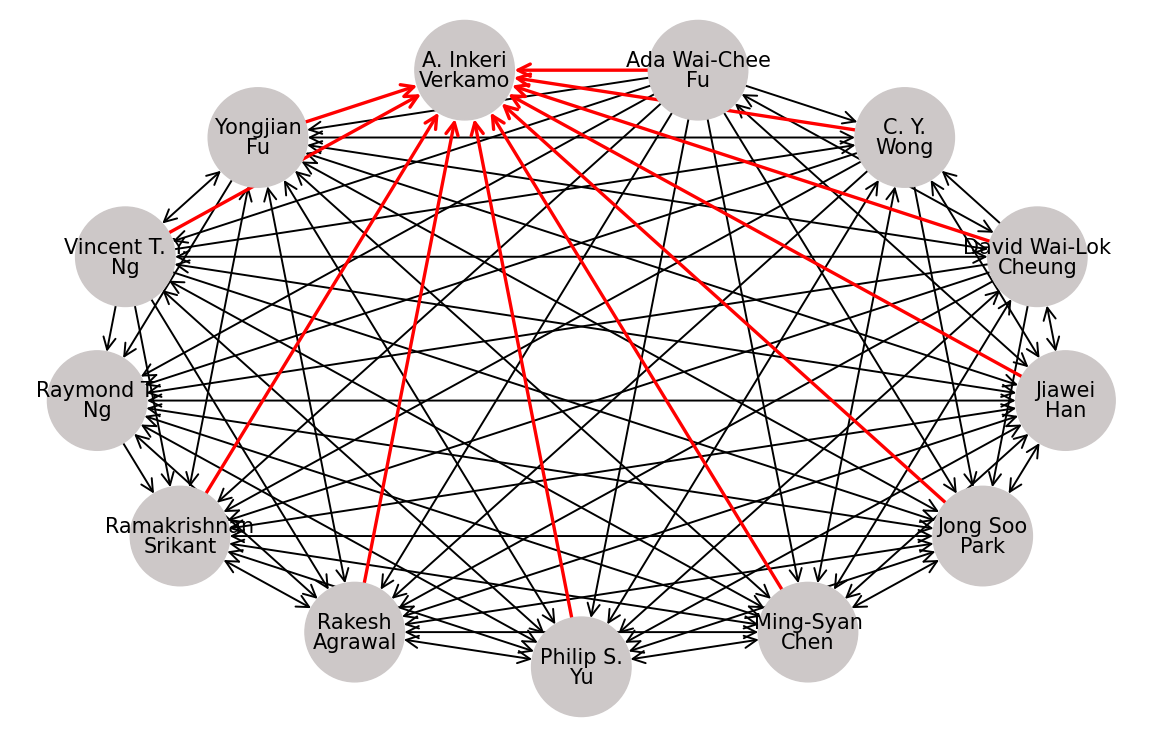

In [6]:
containing = find(uplexes, names, dm)
print(f'{len(containing)} undirected 2-plexes contain all 8 authors; sizes:', sorted(map(len, containing), reverse=True))
(c,) = find(containing, names, ['A. Inkeri Verkamo'], size=13)
print(describe(c, edges, names))
first = ['A. Inkeri Verkamo', 'Ada Wai-Chee Fu']
order = [ids[n] for n in first] + [v for v in sorted(c, key=lambda v: names[v]) if names[v] not in first]
display(Image(draw_plex(c, edges, names, os.path.join(OUTPUT, 'fig7c_undirected_plex.png'),
                        highlight='A. Inkeri Verkamo', order=order)))

## 6. Explore further
`plexes` and `uplexes` hold all results as sets of vertex IDs. For example, list the five largest $(2,2)$-plexes:

In [7]:
for p in sorted(plexes, key=len, reverse=True)[:5]:
    print(len(p), ', '.join(sorted(names[v] for v in p)))

10 Anthony Tomasic, Donald Kossmann, Edward L. Wimmers, Hector Garcia-Molina, Jennifer Widom, Jun Yang, Laura M. Haas, Louiqa Raschid, Patrick Valduriez, Yannis Papakonstantinou
10 Anthony Tomasic, Daniela Florescu, Donald Kossmann, Edward L. Wimmers, Hector Garcia-Molina, Jun Yang, Laura M. Haas, Louiqa Raschid, Patrick Valduriez, Yannis Papakonstantinou
9 Christos Faloutsos, Hans-Peter Kriegel, Jiawei Han, Jong Soo Park, Ming-Syan Chen, Philip S. Yu, Rakesh Agrawal, Ramakrishnan Srikant, Raymond T. Ng
9 David J. DeWitt, Honesty C. Young, Hongjun Lu, Kian-Lee Tan, Kun-Lung Wu, Ming-Ling Lo, Ming-Syan Chen, Philip S. Yu, Yannis E. Ioannidis
9 Daniela Florescu, Donald Kossmann, Edward L. Wimmers, Jennifer Widom, Jun Yang, Laura M. Haas, Louiqa Raschid, Patrick Valduriez, Yannis Papakonstantinou
